# Sistem Rekomendasi Magang — Analisis Dataset

## 1. Pendahuluan
Tujuan tahap ini adalah menilai apakah data pekerjaan dapat digunakan untuk merekomendasikan peran magang sesuai keterampilan mahasiswa. Pertanyaan penelitian: apa isi data, bagaimana kualitasnya, dan seberapa banyak indikasi posisi awal karier?

Bagian pertama berisi EDA. Bagian lanjutan membangun prototipe rekomendasi peran historis setelah data dianalisis. Evaluasi relevansi menunggu label manusia. Skor kecocokan yang kelak dibuat bukan probabilitas diterima perusahaan.

Sumber: [batuhanmtl/job-skill-set](https://huggingface.co/datasets/batuhanmtl/job-skill-set). Satu split bernama `train` adalah nama bawaan sumber, bukan berarti notebook sudah melatih model. Revision dikunci dalam metadata dan skrip unduhan. Menurut dataset card, data berasal dari LinkedIn Job Postings milik Arshkon dan skill diekstrak melalui RecAI. Repositori diperbarui 15 Desember 2024; tanggal pengumpulan setiap lowongan tidak tersedia. Lisensi pada card mengarahkan ke sumber Kaggle, sehingga izin turunan perlu diperiksa sebelum redistribusi.

## Cara menjalankan di VS Code
Buka folder proyek, pasang ekstensi Python dan Jupyter, pilih kernel `.venv/Scripts/python.exe`, kemudian **Run All**. Dependensi ada di `requirements.txt`. CSV sudah tersedia; jangan menjalankan unduhan ulang untuk menjalankan notebook.

## 2. Import library
Pandas membaca dan merangkum data; pathlib menangani lokasi file; ast membaca daftar skill berbentuk teks secara aman; re mencari kata; hashlib memeriksa integritas; matplotlib membuat grafik sederhana.

In [1]:
from pathlib import Path
import ast
import hashlib
import json
import re
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

pd.set_option("display.max_colwidth", 110)
# Mendukung working directory folder proyek maupun folder notebook.
ROOT = Path.cwd().resolve()
if ROOT.name == "notebook":
    ROOT = ROOT.parent
RAW = ROOT / "data" / "raw"
CSV_PATH = RAW / "job_skill_set_train.csv"
assert CSV_PATH.exists(), f"CSV belum ditemukan: {CSV_PATH}"
metadata = json.loads((RAW / "metadata.json").read_text(encoding="utf-8"))
raw_hash_awal = hashlib.sha256(CSV_PATH.read_bytes()).hexdigest()
assert raw_hash_awal == metadata["sha256_csv"], "CSV berbeda dari snapshot unduhan"
print("Dataset:", metadata["dataset"])
print("Revision:", metadata["revision"])
print("Waktu unduh UTC:", metadata["downloaded_at_utc"])

Dataset: batuhanmtl/job-skill-set
Revision: 78e2e843eada1d3c901bc7fb123eaf2dc1c3c36f
Waktu unduh UTC: 2026-11-04T13:31:42.507828+00:00


## 3. Membaca data mentah
CSV adalah konversi utuh dari Parquet asli, tanpa membuang baris atau mengubah teks. Parquet asli disimpan sebagai bukti. Pemeriksaan kesetaraan memastikan konversi tidak mengubah nilai. Dalam Pandas, ukuran menggunakan atribut `df.shape`, **bukan** fungsi `df.shape()`.

In [2]:
df = pd.read_csv(CSV_PATH)
sumber = pd.read_parquet(RAW / "job_skill_set_train.parquet")
pd.testing.assert_frame_equal(df, sumber, check_dtype=False)
print("CSV sama dengan Parquet asli.")
display(df.head())
print("Ukuran (baris, kolom):", df.shape)
print("Nama kolom:", df.columns.tolist())
df.info()

CSV sama dengan Parquet asli.


,job_id,category,job_title,job_description,job_skill_set
0,3902668440,HR,Sr Human Resource Generalist,SUMMARY\nTHE SR. HR GENERALIST PROVIDES HR EXPERTISE ACROSS VARIOUS FUNCTIONS INCLUDING EMPLOYEE RELATIONS...,"['employee relations', 'talent acquisition', 'performance management', 'compensation and benefits', 'emplo..."
1,3905823748,HR,Human Resources Manager,BE PART OF A STELLAR TEAM AT YSB AS THE MANAGER OF HUMAN RESOURCES. JOIN US AS YSB ENTERS A NEW AND VIBRAN...,"['Talent Acquisition', 'Employee Performance Management', 'Legal Compliance', 'Payroll Processing', 'Micro..."
2,3905854799,HR,Director of Human Resources,OUR CLIENT IS A THRIVING ORGANIZATION OFFERING A UNIQUE OPPORTUNITY FOR A DIRECTOR OF HUMAN RESOURCES TO J...,"['Human Resources Management', 'Recruitment', 'Employee Relations', 'Performance Management', 'Compliance ..."
3,3905834061,HR,Chief Human Resources Officer,JOB TITLE: CHIEF HUMAN RESOURCES OFFICER (CHRO)INDUSTRY: ENTERTAINMENT & MEDIA \nJOB DESCRIPTION:EAST 57TH...,"['talent management', 'organizational development', 'HR compliance', 'HR technology systems', 'data-driven..."
4,3906250451,HR,Human Resources Generalist (Hybrid Role),DESCRIPTION\n\n WHO WE ARE \n\nAVI-SPL IS A DIGITAL ENABLEMENT SOLUTIONS PROVIDER WHO TRANSFORMS HOW PEOPL...,"['Microsoft Office', 'Data analysis', 'Employee onboarding', 'Strategic thinking', 'Problem solving', 'Tim..."


Ukuran (baris, kolom): (1167, 5)
Nama kolom: ['job_id', 'category', 'job_title', 'job_description', 'job_skill_set']
<class 'pandas.DataFrame'>
RangeIndex: 1167 entries, 0 to 1166
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   job_id           1167 non-null   int64
 1   category         1167 non-null   str  
 2   job_title        1167 non-null   str  
 3   job_description  1167 non-null   str  
 4   job_skill_set    1167 non-null   str  
dtypes: int64(1), str(4)
memory usage: 4.7 MB


## 4. Pemeriksaan kualitas awal
Null, teks kosong, dan duplikat adalah masalah berbeda. `duplicated()` menghitung pengulangan setelah kemunculan pertama. Semua pemeriksaan di bawah hanya membaca data, belum menghapus apa pun.

In [3]:
display(df.isnull().sum().rename("jumlah_null").to_frame())
print("Duplikat seluruh kolom:", df.duplicated().sum())
print("Duplikat job_id:", df["job_id"].duplicated().sum())
print("Duplikat isi tanpa job_id:", df.duplicated(subset=["category", "job_title", "job_description", "job_skill_set"]).sum())
kolom_teks = ["category", "job_title", "job_description", "job_skill_set"]
kosong = df[kolom_teks].apply(lambda kolom: kolom.fillna("").str.strip().eq("").sum())
display(kosong.rename("null_atau_teks_kosong").to_frame())
display(df[kolom_teks].describe())
display(Markdown(f"**Interpretasi:** terdapat {len(df):,} baris, {df.shape[1]} kolom, "
                 f"{df.isnull().sum().sum()} nilai null dan {df.duplicated().sum()} duplikat baris penuh. "
                 "Data tanpa null belum tentu benar secara semantik; isi deskripsi dan skill tetap perlu ditinjau."))

,jumlah_null
job_id,0
category,0
job_title,0
job_description,0
job_skill_set,0


Duplikat seluruh kolom: 0
Duplikat job_id: 0
Duplikat isi tanpa job_id: 0


,null_atau_teks_kosong
category,0
job_title,0
job_description,0
job_skill_set,0


,category,job_title,job_description,job_skill_set
count,1167,1167,1167,1167
unique,5,723,1167,1167
top,INFORMATION-TECHNOLOGY,Business Development Manager,SUMMARY\nTHE SR. HR GENERALIST PROVIDES HR EXPERTISE ACROSS VARIOUS FUNCTIONS INCLUDING EMPLOYEE RELATIONS...,"['employee relations', 'talent acquisition', 'performance management', 'compensation and benefits', 'emplo..."
freq,240,53,1,1


**Interpretasi:** terdapat 1,167 baris, 5 kolom, 0 nilai null dan 0 duplikat baris penuh. Data tanpa null belum tentu benar secara semantik; isi deskripsi dan skill tetap perlu ditinjau.

## 5. Seluruh kategori pekerjaan
Kategori mengikuti sumber. Kita tidak menambahkan kategori yang tidak didukung data. Persentase dihitung terhadap seluruh baris, termasuk duplikat jika ada.

,category,jumlah,persentase
0,INFORMATION-TECHNOLOGY,240,20.57
1,BUSINESS-DEVELOPMENT,239,20.48
2,FINANCE,236,20.22
3,SALES,232,19.88
4,HR,220,18.85


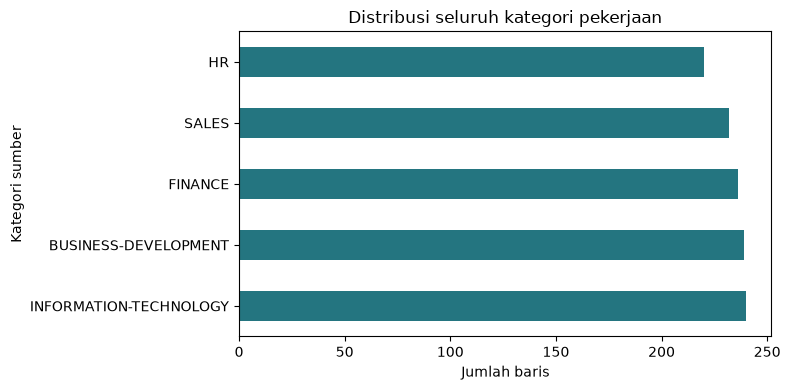

**Interpretasi grafik:** kategori terbesar adalah **INFORMATION-TECHNOLOGY** (240 baris; 20.57%). Proporsi lima kategori relatif seimbang (sekitar 19–21%); ini tidak menjamin keseimbangan level pengalaman. Kategori pekerjaan bukan label relevansi mahasiswa.

In [4]:
kategori = df["category"].value_counts(dropna=False).rename_axis("category").reset_index(name="jumlah")
kategori["persentase"] = (kategori["jumlah"] / len(df) * 100).round(2)
with pd.option_context("display.max_rows", None):
    display(kategori)
ax = kategori.set_index("category")["jumlah"].plot.barh(figsize=(8, 4), color="#247580")
ax.set_xlabel("Jumlah baris")
ax.set_ylabel("Kategori sumber")
ax.set_title("Distribusi seluruh kategori pekerjaan")
plt.tight_layout()
plt.show()
display(Markdown(f"**Interpretasi grafik:** kategori terbesar adalah **{kategori.iloc[0]['category']}** "
                 f"({kategori.iloc[0]['jumlah']} baris; {kategori.iloc[0]['persentase']}%). "
                 "Proporsi lima kategori relatif seimbang (sekitar 19–21%); ini tidak menjamin keseimbangan level pengalaman. Kategori pekerjaan bukan label relevansi mahasiswa."))

## 6. Analisis job_title dan job_description
Judul menunjukkan nama peran; deskripsi berisi konteks, tanggung jawab, dan persyaratan. Periksa frekuensi judul, panjang teks, dan contoh nyata per kategori. Jumlah kata di sini menggunakan pemisahan spasi, bukan tokenisasi NLP.

In [5]:
print("Jumlah judul unik:", df["job_title"].nunique())
display(df["job_title"].value_counts().head(20).rename("jumlah").to_frame())
panjang = pd.DataFrame({
    "karakter_judul": df["job_title"].str.len(),
    "karakter_deskripsi": df["job_description"].str.len(),
    "kata_deskripsi": df["job_description"].str.split().str.len(),
})
display(panjang.describe().round(1))
# Contoh pertama dari setiap kategori, bukan sampel acak yang mewakili seluruh data.
for kategori_nama, grup in df.groupby("category"):
    contoh = grup.iloc[0]
    print("\nKATEGORI:", kategori_nama)
    print("JUDUL:", contoh["job_title"])
    print("DESKRIPSI (700 karakter pertama):", contoh["job_description"][:700])
indikasi_senior = df["job_title"].str.contains(r"\b(?:senior|sr\.?|manager|director|chief|head|lead)\b", case=False, na=False)
print("Judul dengan penanda senior/manajerial:", indikasi_senior.sum())
display(Markdown(f"**Interpretasi:** terdapat {df['job_title'].nunique()} judul unik. "
                 f"{indikasi_senior.sum()} judul memiliki penanda senior/manajerial berdasarkan pola kata. "
                 "Ini indikator heuristik, bukan label pengalaman yang sudah diverifikasi. Contoh teks memakai bahasa Inggris; bahasa seluruh data belum diklasifikasikan otomatis."))

Jumlah judul unik: 723


,jumlah
job_title,
Business Development Manager,53
Human Resources Generalist,34
Business Development Representative,33
Human Resources Manager,28
Information Technology Support Specialist,16
Human Resources Business Partner,15
Finance Manager,15
Director of Finance,13
Human Resources Coordinator,11


,karakter_judul,karakter_deskripsi,kata_deskripsi
count,1167.0,1167.0,1167.0
mean,35.6,3768.3,516.8
std,14.8,2103.1,293.4
min,10.0,167.0,29.0
25%,26.0,2124.0,287.5
50%,33.0,3445.0,471.0
75%,42.0,4932.5,682.0
max,147.0,13639.0,1851.0



KATEGORI: BUSINESS-DEVELOPMENT
JUDUL: Business Development Manager - VMS/MSP
DESKRIPSI (700 karakter pertama): BUSINESS DEVELOPMENT MANAGER – MSP/VMS
HYBRID ROLE
MUST HAVE EXPERIENCE WORKING FOR A STAFFING COMPANY SELLING TO LARGE MSP’S
ABOUT THE ROLE:
AS A BUSINESS DEVELOPMENT MANAGER - MSP/VMS, YOU WILL PLAY A CRUCIAL ROLE IN DRIVING NEW BUSINESS GROWTH THROUGH MANAGED SERVICE PROVIDERS (MSPS) AND VENDOR MANAGEMENT SYSTEMS (VMS) PLATFORMS. YOU WILL LEVERAGE YOUR EXPERTISE IN THE CONTINGENT WORKFORCE INDUSTRY TO IDENTIFY AND CULTIVATE RELATIONSHIPS WITH KEY DECISION-MAKERS, DEVELOP COMPELLING PROPOSALS, AND ULTIMATELY SECURE NEW PARTNERSHIPS THAT EXPAND OUR REACH AND REVENUE.
RESPONSIBILITIES:
PROSPECTING AND LEAD GENERATION:
PROACTIVELY IDENTIFY AND QUALIFY POTENTIAL MSP AND VMS PARTNERS ACROSS DIV

KATEGORI: FINANCE
JUDUL: Director, Finance
DESKRIPSI (700 karakter pertama): JOB DESCRIPTION FOR DIRECTOR ROLE

CHEWY IS LOOKING FOR A DIRECTOR OF FINANCE IN PLANTATION, FL OR BELLEVUE, 

**Interpretasi:** terdapat 723 judul unik. 506 judul memiliki penanda senior/manajerial berdasarkan pola kata. Ini indikator heuristik, bukan label pengalaman yang sudah diverifikasi. Contoh teks memakai bahasa Inggris; bahasa seluruh data belum diklasifikasikan otomatis.

## 7. Analisis job_skill_set
Kolom ini berupa **string berisi representasi list**, bukan list Python langsung. `ast.literal_eval` membaca literal tanpa menjalankan kode seperti `eval`. Kegagalan parsing ditampilkan, tidak disembunyikan.

Untuk hitungan eksplorasi saja, huruf kecil dan spasi tepi dinormalisasi pada variabel terpisah. Satu skill dihitung maksimal sekali per baris lowongan. Sinonim seperti MS Excel dan Microsoft Excel belum disatukan. Skill hasil RecAI bukan penilaian pakar dan dapat memuat pendidikan atau persyaratan lain.

In [6]:
def baca_skill(teks):
    if pd.isna(teks):
        return None
    try:
        hasil = ast.literal_eval(teks)
    except (ValueError, SyntaxError):
        return None
    if not isinstance(hasil, list) or not all(isinstance(item, str) for item in hasil):
        return None
    return hasil

skill_list = df["job_skill_set"].apply(baca_skill)
gagal = skill_list.isna()
print("Baris gagal parsing:", gagal.sum())
display(df.loc[gagal, ["job_id", "job_skill_set"]].head())
print("List kosong:", skill_list.dropna().apply(len).eq(0).sum())
display(skill_list.dropna().apply(len).describe().rename("jumlah_skill_per_baris").to_frame())
print("Contoh teks asli:", df["job_skill_set"].iloc[0])
print("Contoh hasil parsing:", skill_list.iloc[0])
skill_per_lowongan = skill_list.dropna().apply(
    lambda daftar: sorted({skill.strip().lower() for skill in daftar if skill.strip()})
)
frekuensi_skill = skill_per_lowongan.explode().dropna().value_counts()
display(frekuensi_skill.head(25).rename("jumlah_baris_lowongan").to_frame())
display(Markdown(f"**Interpretasi:** {len(skill_list) - gagal.sum()} baris berhasil dibaca sebagai list string; "
                 f"ditemukan {len(frekuensi_skill)} bentuk skill unik setelah normalisasi ringan. "
                 "Frekuensi tinggi tidak berarti skill paling penting; soft skill umum dapat mendominasi pencocokan."))

Baris gagal parsing: 0


,job_id,job_skill_set


List kosong: 0


,jumlah_skill_per_baris
count,1167.000000
mean,17.851757
std,4.980524
min,5.000000
25%,15.000000
50%,18.000000
75%,20.000000
max,43.000000


Contoh teks asli: ['employee relations', 'talent acquisition', 'performance management', 'compensation and benefits', 'employment laws and regulations', 'analytical skills', 'employee benefits administration', 'HR policies and procedures', 'recruitment strategies', 'FMLA', 'ADA', 'communication', 'interpersonal skills', 'collaboration', 'influence', 'change management', 'professional development', 'payroll processing', 'job design', 'salary administration', 'human capital management system', 'HR audits and assessments', 'FLSA', 'ERISA', 'EEOC guidelines', 'confidentiality', 'intellectual curiosity']
Contoh hasil parsing: ['employee relations', 'talent acquisition', 'performance management', 'compensation and benefits', 'employment laws and regulations', 'analytical skills', 'employee benefits administration', 'HR policies and procedures', 'recruitment strategies', 'FMLA', 'ADA', 'communication', 'interpersonal skills', 'collaboration', 'influence', 'change management', 'professional de

,jumlah_baris_lowongan
job_skill_set,
communication,1092
problem solving,878
adaptability,588
teamwork,569
collaboration,341
leadership,325
time management,316
interpersonal skills,288
customer service,272


**Interpretasi:** 1167 baris berhasil dibaca sebagai list string; ditemukan 4984 bentuk skill unik setelah normalisasi ringan. Frekuensi tinggi tidak berarti skill paling penting; soft skill umum dapat mendominasi pencocokan.

## 8. Indikasi intern, internship, trainee, dan entry-level
Pencarian tidak peka huruf besar/kecil dan memakai batas kata agar `intern` tidak mengenai `international` atau `internal`. Bentuk jamak dan variasi tanda hubung entry-level ikut diperiksa. Judul dan deskripsi dihitung terpisah. Hitungan antaristilah dapat tumpang tindih.

**Batasan:** deskripsi dapat menyebut pengalaman magang sebelumnya atau tugas membimbing intern. Trainee dan entry-level juga tidak selalu magang. Tidak ditemukannya kata ini bukan bukti pasti bahwa posisi tidak menerima pemula.

In [7]:
pola = {
    "intern": r"\binterns?\b",
    "internship": r"\binternships?\b",
    "trainee": r"\btrainees?\b",
    "entry-level": r"\bentry[\s\-‐‑–—]*level\b",
}
hit_judul = pd.DataFrame({nama: df["job_title"].str.contains(regex, case=False, na=False)
                         for nama, regex in pola.items()})
hit_deskripsi = pd.DataFrame({nama: df["job_description"].str.contains(regex, case=False, na=False)
                             for nama, regex in pola.items()})
ringkasan_kata = pd.DataFrame({
    "di_judul": hit_judul.sum(),
    "di_deskripsi": hit_deskripsi.sum(),
    "di_salah_satu": (hit_judul | hit_deskripsi).sum(),
})
display(ringkasan_kata)
mask_judul = hit_judul.any(axis=1)
mask_deskripsi = hit_deskripsi.any(axis=1)
print("Baris unik dengan indikasi di judul:", mask_judul.sum())
print("Baris unik dengan indikasi di judul/deskripsi:", (mask_judul | mask_deskripsi).sum())
print("Hanya di deskripsi:", (mask_deskripsi & ~mask_judul).sum())
print("Seluruh kandidat dari judul (belum divalidasi manual):")
with pd.option_context("display.max_rows", None, "display.max_colwidth", None):
    display(df.loc[mask_judul, ["job_id", "category", "job_title"]])
print("Kategori kandidat dari judul:")
display(df.loc[mask_judul, "category"].value_counts().rename("jumlah").to_frame())
# Tampilkan konteks setiap kecocokan pada deskripsi untuk pemeriksaan manual.
pola_gabungan = "|".join(pola.values())
bukti = []
for indeks in df.index[mask_deskripsi]:
    teks = df.at[indeks, "job_description"]
    for cocok in re.finditer(pola_gabungan, teks, flags=re.IGNORECASE):
        bukti.append({
            "job_id": df.at[indeks, "job_id"],
            "job_title": df.at[indeks, "job_title"],
            "kata": cocok.group(),
            "konteks": teks[max(0, cocok.start()-100):cocok.end()+150],
        })
with pd.option_context("display.max_rows", None, "display.max_colwidth", None):
    display(pd.DataFrame(bukti))
display(Markdown(f"**Interpretasi:** {mask_judul.sum()} dari {len(df)} baris "
                 f"({mask_judul.mean():.2%}) memiliki indikasi di judul. "
                 f"{(mask_deskripsi & ~mask_judul).sum()} baris hanya cocok di deskripsi. "
                 "Seluruhnya merupakan kandidat pemeriksaan, bukan jumlah magang terverifikasi."))

,di_judul,di_deskripsi,di_salah_satu
intern,20,30,33
internship,5,34,35
trainee,4,5,5
entry-level,8,36,41


Baris unik dengan indikasi di judul: 37
Baris unik dengan indikasi di judul/deskripsi: 86
Hanya di deskripsi: 49
Seluruh kandidat dari judul (belum divalidasi manual):


,job_id,category,job_title
25,3901662440,HR,Human Resources Intern
52,3905297142,HR,Human Resources Specialist 1/Trainee 1/2 - HELPS
62,3898137449,HR,Human Resources Summer 2024 Internship
67,3904406321,HR,Human Resources Intern
73,3899526653,HR,Human Resources Intern
100,3898173889,HR,"Intern, Talent Management, Human Resources"
140,3894550753,HR,Human Resources Coordinator (Entry Level)
234,3900980589,INFORMATION-TECHNOLOGY,Entry-level Information Technology (IT) Role
260,3891071402,INFORMATION-TECHNOLOGY,Entry-level Information Technology (IT) Role
264,3891072419,INFORMATION-TECHNOLOGY,Information Technology Intern


Kategori kandidat dari judul:


,jumlah
category,
BUSINESS-DEVELOPMENT,9
FINANCE,8
HR,7
INFORMATION-TECHNOLOGY,7
SALES,6


,job_id,job_title,kata,konteks
0,3905823748,Human Resources Manager,INTERNS,"AUDITS WITH PERSONNEL PROCESS AND DOCUMENTATION.COORDINATE WITH LEADERSHIP TO ATTRACT AND ON-BOARD INTERNS AND VOLUNTEERS.CONDUCT BACKGROUND CHECKS FOR INTERNS AND VOLUNTEERS, AS NEEDED.ENSURE ALL AGENCY HANDBOOKS, OPERATION MANUALS, AND PROGRAM MANUALS FO"
1,3905823748,Human Resources Manager,INTERNS,"DINATE WITH LEADERSHIP TO ATTRACT AND ON-BOARD INTERNS AND VOLUNTEERS.CONDUCT BACKGROUND CHECKS FOR INTERNS AND VOLUNTEERS, AS NEEDED.ENSURE ALL AGENCY HANDBOOKS, OPERATION MANUALS, AND PROGRAM MANUALS FOLLOW REGULATORY AND AGENCY GUIDELINES.ACT AS LIAISON"
2,3902344478,Junior Human Resources Consultant,INTERNS,"THEY ARE APPLIED CORRECTLY, PARTICIPATE IN HR-RELATED AUDITS, GO TO CAREER FAIRS, AND INTERACT WITH INTERNS AND NEW HIRES PERTAINING TO ONBOARDING AND ORIENTATION ACTIVITIES.\nREQUIRED SKILLS & EXPERIENCEBACHELOR’S DEGREE IN HUMAN RESOURCES AND SOME PROFESSI"
3,3901661179,Chief Human Resource Officer,INTERNS,"ES AND EDUCATIONAL OPPORTUNITIES.RESPONSIBLE FOR ORIENTATION PROGRAM OF NEW EMPLOYEES, CONTRACTORS, INTERNS, AND STUDENTS.REVIEWS, TRACKS, AND DOCUMENTS COMPLIANCE WITH MANDATORY AND NON-MANDATORY TRAINING, CONTINUING EDUCATION, AND WORK ASSESSMENTS. THIS M"
4,3900082118,Human Resources Co-Op - Summer 2024,INTERN,NG DISCREPENCIES BETWEEN HR SYSTEMS SET UP CAREER FAIRS AND ATTEND AS NEEDED SUPPORTS THE CO-OP AND INTERN PROGRAMS ASSIST WITH HR PROJECTS AND ADMINISTRATION\n\n\n SECONDARY DUTIES:\n\n N/A\n\n\n EDUCATION AND/OR EXPERIENCE:\n\n ENROLLMENT IN A 4 YEAR ACCREDITED DE
5,3905297142,Human Resources Specialist 1/Trainee 1/2 - HELPS,TRAINEE,"MINIMUM QUALIFICATIONS\n\nFOR APPOINTMENT TO HUMAN RESOURCES SPECIALIST TRAINEE 1:\n\n REACHABLE FOR APPOINTMENT ON CURRENT CIVIL SERVICE ELIGIBLE LIST USED FOR FILLING THIS TITLE; OR ONE YEAR OF PERMANENT, COMPETITIVE CLASS SERVIC"
6,3905297142,Human Resources Specialist 1/Trainee 1/2 - HELPS,TRAINEE,UMAN RESOURCES); OR\n\n A BACHELOR'S DEGREE OR HIGHER.\n\nFOR APPOINTMENT TO HUMAN RESOURCES SPECIALIST TRAINEE 2\n\n A BACHELOR'S DEGREE AND ONE YEAR OF PROFESSIONAL HUMAN RESOURCES EXPERIENCE; OR MASTER'S OR HIGHER DEGREE IN A RELATED FIELD.\n\nFOR APPOINTMENT TO
7,3905297142,Human Resources Specialist 1/Trainee 1/2 - HELPS,TRAINEE,UNITIES EXAMINATION LIST ARE ENCOURAGED TO APPLY.\n\nDUTIES DESCRIPTION\n\nHUMAN RESOURCES SPECIALIST 1/TRAINEE 1/2 WILL SERVE INTERNAL AND EXTERNAL CUSTOMERS AND PERFORM DUTIES RELATED TO THE AREAS ASSIGNED. THEY WILL ASSIST THE LEAVE UNIT IN ADMINISTERING VAR
8,3902876855,Human Resources Coordinator,ENTRY-LEVEL,"RVIEWS FOR INTERNAL TEAMS. GENERATE OFFER LETTERS FOR FINALIST CANDIDATES.MAY HANDLE RECRUITMENT OF ENTRY-LEVEL POSITIONS AS NEEDED.OTHER DUTIES AS ASSIGNED. \nSKILLS, QUALIFICATIONS AND EDUCATIONSTRONG DESIRE TO PURSUE CAREER IN A HUMAN RESOURCES DEPARTMENT.EXP"
9,3898137449,Human Resources Summer 2024 Internship,INTERNSHIP,"ONE OF THE BEST PLACES TO WORK IN COMMERCIAL REAL ESTATE! \n\nNORTHMARQ IS OFFERING A HUMAN RESOURCES INTERNSHIP AT THEIR MINNEAPOLIS, MN (BLOOMINGTON, MN) HEADQUARTERS OFFICE. THIS POSITION WILL BE RESPONSIBLE FOR OVERALL HUMAN RESOURCES ASSISTANCE. THE INTERN"


**Interpretasi:** 37 dari 1167 baris (3.17%) memiliki indikasi di judul. 49 baris hanya cocok di deskripsi. Seluruhnya merupakan kandidat pemeriksaan, bukan jumlah magang terverifikasi.

## 9. Kesesuaian untuk rekomendasi magang mahasiswa
Dataset ini **cocok sebagai bahan eksplorasi pencocokan keterampilan dan peran pekerjaan**, tetapi **belum cukup sebagai katalog lowongan magang terverifikasi**.

- Judul, deskripsi, kategori, dan skill dapat mendukung pencocokan berbasis konten. Skill ekstraksi otomatis perlu audit manual terhadap deskripsi.
- Cakupan hanya lima kategori sumber; tidak mewakili semua jurusan mahasiswa.
- Ada penanda senior/manajerial. Kandidat pemula harus ditinjau berdasarkan persyaratan pengalaman, pendidikan, dan isi pekerjaan, bukan mengganti nama posisi menjadi “Intern”.
- Tidak ada kolom perusahaan, lokasi, level pengalaman, jenis kontrak, tanggal publikasi, URL lamaran, atau status aktif yang terstruktur. Informasi yang mungkin disebut di teks belum tervalidasi. Rekomendasi berdasarkan domisili belum dapat dibangun dari kolom yang tersedia.
- Tidak ada profil mahasiswa, interaksi pengguna, atau label relevansi. Kualitas rekomendasi kelak membutuhkan pasangan mahasiswa–pekerjaan yang dinilai manusia dengan kriteria jelas; kategori bukan ground truth relevansi.
- Tanggal pembaruan repositori bukan tanggal lowongan. Jangan menyebut data ini sebagai magang yang masih terbuka atau representatif untuk Indonesia.

**Keputusan tahap dataset:** pertahankan snapshot ini sebagai bahan EDA. Sebelum modeling magang, tinjau kandidat secara manual dan lengkapi dengan data magang yang relevan. Jika memakai seluruh data ini, batasi klaim menjadi rekomendasi peran pekerjaan berdasarkan skill, bukan rekomendasi lowongan magang aktif.

### Temuan konkret dan tinjauan contoh

Hasil eksekusi: 37 judul (3,17%) memiliki indikasi awal karier; 25 di antaranya memuat intern atau internship. Sebanyak 86 baris cocok di judul atau deskripsi, termasuk 49 yang hanya cocok di deskripsi. Ada 506 judul dengan penanda senior/manajerial; ini bukan klasifikasi level pengalaman final.

- `job_id=3905823748`, **Human Resources Manager**: deskripsi menyebut merekrut/memeriksa latar belakang intern dan relawan. Ini contoh kecocokan kata yang tidak menunjukkan posisi magang.
- `job_id=3898137449`, **Human Resources Summer 2024 Internship**: judul dan deskripsi mendukung bahwa perannya magang, tetapi menyebut musim panas 2024, sehingga tidak membuktikan masih dibuka pada November 2026.
- `job_id=3894550753`, **Human Resources Coordinator (Entry Level)**: deskripsi menyebut posisi entry level. Status pemula tidak otomatis berarti magang.

Tiga contoh ini ditinjau dari teks sumber, bukan validasi manual menyeluruh terhadap semua kandidat.

## 10. Alternatif yang lebih relevan
Perbandingan berikut berasal dari halaman publik yang diperiksa 4 November 2026, **bukan hasil unduhan atau audit penuh dataset alternatif**. Dataset utama tetap sesuai pilihan pengguna.

| Kandidat | Jumlah dan periode yang dilaporkan | Kolom/cakupan penting | Kelebihan dan batasan |
|---|---|---|---|
| [batuhanmtl/job-skill-set](https://huggingface.co/datasets/batuhanmtl/job-skill-set) | 1.167 baris hasil pembacaan lokal; repositori diperbarui Desember 2024 | job_id, category, job_title, job_description, job_skill_set | Ringan dan punya skill; pekerjaan umum, tanpa status magang terstruktur. |
| [JobSelect/Job-Descriptions-JobAnalyze_6k](https://huggingface.co/datasets/JobSelect/Job-Descriptions-JobAnalyze_6k) | Viewer menampilkan 609 baris, bukan 6.000 meski nama mengandung 6k; contoh year 2026 | role, type, job_desc, year, qualification, experience, tech_skills, soft_skills | Ada Internship dan skill, ringan; hanya dua nilai role pada viewer. Contoh label Junior dapat memuat kebutuhan pengalaman beberapa tahun, sehingga perlu audit label, duplikat, dan asal data. Halaman menyatakan MIT. |
| [HeadcountLabs/internships](https://huggingface.co/datasets/HeadcountLabs/internships) | Card melaporkan 150.057 pekerjaan; snapshot 19 Oktober 2026 | title, employment_type, employer_name, lokasi, tanggal, posting_url, currentness | Lebih khusus magang/co-op; ODbL 1.0. Deskripsi dan daftar skill tidak disertakan, sehingga tidak langsung cukup untuk pencocokan skill. Seleksi berbasis kata kunci tetap perlu validasi; status snapshot tidak menjamin masih aktif hari ini. |

**Saran:** audit sampel JobSelect bila fokus studi dipersempit ke AI; untuk lintas jurusan dan konteks Indonesia, kumpulkan data resmi magang dari pusat karier kampus/perusahaan dengan izin yang sesuai, mencatat skill, syarat, lokasi, tanggal, dan URL sumber. HeadcountLabs dapat menjadi kandidat katalog magang, tetapi perlu sumber deskripsi yang sah. Alternatif di atas belum otomatis menggantikan dataset utama.

## 11. Verifikasi akhir tahap EDA
Hash data mentah harus tetap sama. Tahap berikut menggunakan data turunan dan tidak mengubah raw.

In [8]:
assert hashlib.sha256(CSV_PATH.read_bytes()).hexdigest() == raw_hash_awal
assert hashlib.sha256((RAW / "job_skill_set_train.parquet").read_bytes()).hexdigest() == metadata["sha256_parquet"]
print("Verifikasi selesai: CSV dan Parquet mentah tidak berubah.")

Verifikasi selesai: CSV dan Parquet mentah tidak berubah.


# Lanjutan: eksperimen rekomendasi peran
## 12. Preprocessing dan feature engineering
Kode bersama di `model/recommender.py` dipakai notebook dan API. Salinan data dinormalisasi dengan Unicode NFKC, huruf kecil, dan perapian spasi. Tanda C++, C#, dan .NET dipertahankan. Tidak ada pemetaan sinonim spekulatif. Null penting dan duplikat dibuang hanya jika ada. Pada snapshot ini tidak ada baris yang dibuang.

Kolom kandidat magang diturunkan dari kata intern/internship pada judul, bukan label magang aktif. Data turunan disimpan di `data/jobs_clean.csv`. Lokasi tidak menjadi fitur karena belum tersedia secara terstruktur.

In [9]:
import sys
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import numpy as np
from model.recommender import prepare_jobs, build_model, recommend, save_model, load_model
jobs = prepare_jobs(df)
print("Sebelum:", df.shape, "Sesudah:", jobs.shape)
print("Kandidat magang:", jobs["internship_candidate"].sum())
export = jobs.drop(columns=["content"]).copy()
export["skills"] = export["skills"].apply(json.dumps)
export.to_csv(ROOT / "data/jobs_clean.csv", index=False)
display(jobs[["job_title", "skills", "internship_candidate"]].head())

Sebelum: (1167, 5) Sesudah: (1167, 9)
Kandidat magang: 25


,job_title,skills,internship_candidate
0,Sr Human Resource Generalist,"[ada, analytical skills, change management, collaboration, communication, compensation and benefits, confi...",False
1,Human Resources Manager,"[adaptability, attention to detail, background checks, collaboration, communication, employee performance ...",False
2,Director of Human Resources,"[adaptability, attention to detail, collaboration, communication, compliance with labor laws, computer ski...",False
3,Chief Human Resources Officer,"[change management, collaboration, communication, compensation and benefits strategies, creativity, data-d...",False
4,Human Resources Generalist (Hybrid Role),"[attention to detail, change management, communication, compliance reporting, confidentiality, conflict ne...",False


**Interpretasi:** jumlah baris tetap; kolom tambahan adalah turunan dari sumber. Filter diterapkan sebelum ranking, sehingga pekerjaan umum tidak otomatis disebut magang.

## 13. Eksperimen 1 — TF-IDF + cosine similarity
Fitur pekerjaan menggabungkan judul, skill, dan deskripsi. Profil menggabungkan skill dan minat. TF-IDF memberi bobot lebih besar pada kata/frasa khas, dengan unigram/bigram, stop words Inggris, sublinear TF, dan batas 30.000 fitur. Parameter ini baseline, belum hasil tuning. Skor cosine × 100 bukan peluang diterima.

[Dokumentasi TF-IDF](https://scikit-learn.org/stable/modules/generated/sklearn.feature_extraction.text.TfidfVectorizer.html). Empat profil berikut **skenario demonstrasi buatan**, bukan data mahasiswa penelitian.

In [10]:
bundle = build_model(jobs)
print("Matriks teks:", bundle["text_matrix"].shape)
print("Matriks skill:", bundle["skill_matrix"].shape)
profiles = [
    {"profile_id": "demo_data", "skills": ["python", "sql", "data analysis", "excel"], "interest": "data analytics"},
    {"profile_id": "demo_hr", "skills": ["communication", "recruitment", "microsoft office"], "interest": "human resources"},
    {"profile_id": "demo_finance", "skills": ["financial analysis", "accounting", "microsoft excel"], "interest": "finance accounting"},
    {"profile_id": "demo_sales", "skills": ["sales", "negotiation", "communication"], "interest": "business development"},
]
for profile in profiles:
    result = recommend(bundle, profile["skills"], profile["interest"])
    print(profile["profile_id"])
    display(pd.DataFrame(result["results"])[["job_id", "job_title", "score", "matched_skills"]])
    print("Skill di luar katalog persis:", result["unknown_skills"])

Matriks teks: (1167, 30000)
Matriks skill: (1167, 4984)
demo_data


,job_id,job_title,score,matched_skills
0,3894617437,Finance Intern,4.80,"[data analysis, excel]"
1,3898173889,"Intern, Talent Management, Human Resources",3.86,[data analysis]
2,3888489415,Finance & Investor Relations Intern (Summer 2024),3.74,[]
3,3903476020,Engineering Business Development Specialist Intern,3.46,[data analysis]
4,3889113843,Early Careers: Accounting/Finance - Internship Summer 2024 -Philadelphia,2.53,[data analysis]


Skill di luar katalog persis: []
demo_hr


,job_id,job_title,score,matched_skills
0,3898137449,Human Resources Summer 2024 Internship,12.63,"[communication, microsoft office]"
1,3904406321,Human Resources Intern,12.03,"[communication, recruitment]"
2,3901662440,Human Resources Intern,11.32,[communication]
3,3898173889,"Intern, Talent Management, Human Resources",8.95,[communication]
4,3891072419,Information Technology Intern,7.69,"[communication, microsoft office]"


Skill di luar katalog persis: []
demo_finance


,job_id,job_title,score,matched_skills
0,3904947096,Finance and Accounting Intern,11.25,"[accounting, microsoft excel]"
1,3884853986,2024 Finance Summer Internship,7.69,"[accounting, financial analysis]"
2,3889113843,Early Careers: Accounting/Finance - Internship Summer 2024 -Philadelphia,6.34,[financial analysis]
3,3902757119,Accounting and Finance Intern,6.26,[accounting]
4,3894617437,Finance Intern,6.14,[]


Skill di luar katalog persis: []
demo_sales


,job_id,job_title,score,matched_skills
0,3901625868,Summer Intern Business Development,5.31,[communication]
1,3886450064,Business Development Intern,4.64,[communication]
2,3902788334,Business Development Intern,4.42,[communication]
3,3902366590,Business Development Intern (Remote),4.27,[communication]
4,3895234940,Medical Device Sales Internship- KENTUCKY,4.15,"[communication, negotiation, sales]"


Skill di luar katalog persis: []


**Interpretasi:** ini keluaran demonstrasi, bukan bukti efektivitas. Skill di luar katalog persis masih mungkin muncul dalam teks deskripsi; sinonim belum disatukan.

## 14. Eksperimen 2 — KNN dengan fitur skill biner
Representasi skill biner menunjukkan ada/tidaknya skill. KNN memakai cosine distance dan tidak memakai deskripsi atau minat bebas. Karena fiturnya berbeda, eksperimen ini berbeda dari TF-IDF deskripsi.

KNN pada TF-IDF dan cosine yang sama secara matematis ekuivalen dengan cosine langsung. Uji pertama di bawah membuktikannya, bukan mengklaim dua algoritma independen. [Dokumentasi KNN](https://scikit-learn.org/stable/modules/generated/sklearn.neighbors.NearestNeighbors.html).

In [11]:
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics.pairwise import cosine_similarity
query = bundle["vectorizer"].transform(["python sql data analysis"])
knn_teks = NearestNeighbors(metric="cosine", algorithm="brute").fit(bundle["text_matrix"])
distances, indices = knn_teks.kneighbors(query, n_neighbors=len(jobs))
cosine = cosine_similarity(query, bundle["text_matrix"]).ravel()
print("KNN teks = cosine teks:", np.allclose(1-distances[0], cosine[indices[0]]))
for profile in profiles:
    result = recommend(bundle, profile["skills"], profile["interest"], method="knn")
    print(profile["profile_id"])
    display(pd.DataFrame(result["results"])[["job_id", "job_title", "score", "matched_skills"]])

KNN teks = cosine teks: True
demo_data


,job_id,job_title,score,matched_skills
0,3894617437,Finance Intern,25.00,"[data analysis, excel]"
1,3898137449,Human Resources Summer 2024 Internship,15.81,[data analysis]
2,3886450064,Business Development Intern,14.43,[data analysis]
3,3891263924,Intern - Finance and Accounting,14.43,[data analysis]
4,3903476020,Engineering Business Development Specialist Intern,13.87,[data analysis]


demo_hr


,job_id,job_title,score,matched_skills
0,3898137449,Human Resources Summer 2024 Internship,36.51,"[communication, microsoft office]"
1,3891072419,Information Technology Intern,34.82,"[communication, microsoft office]"
2,3894617437,Finance Intern,28.87,"[communication, microsoft office]"
3,3904406321,Human Resources Intern,28.87,"[communication, recruitment]"
4,3894248984,Program Finance Intern,19.25,[communication]


demo_finance


,job_id,job_title,score,matched_skills
0,3884853986,2024 Finance Summer Internship,29.81,"[accounting, financial analysis]"
1,3904947096,Finance and Accounting Intern,24.08,"[accounting, microsoft excel]"
2,3894248984,Program Finance Intern,19.25,[microsoft excel]
3,3891263924,Intern - Finance and Accounting,16.67,[accounting]
4,3901662440,Human Resources Intern,16.01,[microsoft excel]


demo_sales


,job_id,job_title,score,matched_skills
0,3895234940,Medical Device Sales Internship- KENTUCKY,38.73,"[communication, negotiation, sales]"
1,3894248984,Program Finance Intern,19.25,[communication]
2,3898137449,Human Resources Summer 2024 Internship,18.26,[communication]
3,3899526653,Human Resources Intern,18.26,[communication]
4,3891072419,Information Technology Intern,17.41,[communication]


**Interpretasi KNN:** perubahan peringkat berasal dari representasi skill biner. Skor tinggi bukan bukti memenuhi persyaratan pekerjaan.

## 15. Eksperimen 3 — pretrained embedding
Eksperimen menggunakan [all-MiniLM-L6-v2](https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2), revision `1110a243fdf4706b3f48f1d95db1a4f5529b4d41`. Model pretrained mengubah teks menjadi 384 dimensi; tidak ada fine-tuning di proyek ini. [Dot product vektor ternormalisasi ekuivalen dengan cosine](https://sbert.net/docs/sentence_transformer/usage/semantic_textual_similarity.html).

Judul dan skill dipakai sebagai teks pekerjaan. Deskripsi panjang tidak dimasukkan agar biaya dan pemotongan token lebih terkendali. Jumlah teks yang melewati batas token diperiksa secara eksplisit. Perbedaan hasil dengan TF-IDF berasal dari model sekaligus representasi input, sehingga belum merupakan eksperimen terkontrol yang hanya mengganti algoritma.

Model disimpan lokal setelah unduhan pertama. Untuk mesin baru, pasang `requirements-embedding.txt`; sel ini mengunduh revision yang sama jika model lokal belum ada. Cache tetap di folder proyek. Jika hanya menjalankan aplikasi TF-IDF/KNN, dependensi embedding tidak diperlukan.

In [12]:
import os
os.environ["HF_HOME"] = str(ROOT / "model/artifacts/hf_cache")
os.environ["HF_HUB_DISABLE_XET"] = "1"
from sentence_transformers import SentenceTransformer
from time import perf_counter
embedding_path = ROOT / "model/artifacts/embedding_model"
if (embedding_path / "config.json").exists():
    encoder = SentenceTransformer(str(embedding_path), device="cpu", local_files_only=True)
else:
    encoder = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2",
        revision="1110a243fdf4706b3f48f1d95db1a4f5529b4d41",
        cache_folder=str(ROOT / "model/artifacts/hf_cache"), device="cpu")
    encoder.save_pretrained(str(embedding_path))
candidates = jobs.loc[jobs["internship_candidate"]].reset_index(drop=True)
texts = candidates["job_title"] + ". Skills: " + candidates["skills"].str.join(", ")
lengths = [len(encoder.tokenizer(text, truncation=False)["input_ids"]) for text in texts]
print("Maksimum token:", max(lengths), "Batas encoder:", encoder.max_seq_length)
print("Teks yang dipotong:", sum(length > encoder.max_seq_length for length in lengths))
vectors = encoder.encode(texts.tolist(), normalize_embeddings=True, show_progress_bar=False)
print("Matriks embedding kandidat:", vectors.shape)
embedding_rankings = {}
embedding_elapsed = 0
for profile in profiles:
    start = perf_counter()
    text = profile["interest"] + ". Skills: " + ", ".join(profile["skills"])
    query_vector = encoder.encode([text], normalize_embeddings=True, show_progress_bar=False)[0]
    scores = vectors @ query_vector
    order = sorted(range(len(candidates)), key=lambda i: (-float(scores[i]), int(candidates.iloc[i]["job_id"])))
    embedding_rankings[profile["profile_id"]] = candidates.iloc[order]["job_id"].astype(int).tolist()
    embedding_elapsed += perf_counter()-start
    result = candidates.iloc[order[:5]][["job_id", "job_title"]].copy()
    result["cosine_similarity"] = scores[order[:5]]
    print(profile["profile_id"])
    display(result)
embedding_ms = embedding_elapsed*1000/len(profiles)
np.save(ROOT / "model/artifacts/internship_embeddings.npy", vectors)
_ = (ROOT / "model/artifacts/embedding_rankings.json").write_text(json.dumps(embedding_rankings, indent=2), encoding="utf-8")

C:\Users\yosep\Documents\MECIN-LENING\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 1545.80it/s]

Maksimum token: 78 Batas encoder: 256
Teks yang dipotong: 0


Matriks embedding kandidat: (25, 384)


demo_data


... (3 outputs left out)

demo_finance


,job_id,job_title,cosine_similarity
15,3904947096,Finance and Accounting Intern,0.772551
16,3894617437,Finance Intern,0.726819
17,3902757119,Accounting and Finance Intern,0.726225
12,3891263924,Intern - Finance and Accounting,0.694066
11,3894248984,Program Finance Intern,0.683286


demo_sales


,job_id,job_title,cosine_similarity
20,3902366590,Business Development Intern (Remote),0.724953
21,3902953318,Marketing & Business Development Intern,0.663877
19,3902788334,Business Development Intern,0.649886
23,3886450064,Business Development Intern,0.639254
18,3901625868,Summer Intern Business Development,0.593698


**Interpretasi embedding:** 25 kandidat menghasilkan vektor 384 dimensi; maksimum input 78 token, sehingga tidak ada pemotongan pada batas 256 token. Profil HR dan finance menghasilkan peran bidang terkait di urutan atas. Profil data analytics justru menampilkan Finance Intern dan peran lain; ini menunjukkan keterbatasan katalog dan bahwa kemiripan semantik tidak menjamin tersedianya peran ideal. Tidak ada klaim embedding lebih akurat sebelum penilaian manusia.

## 16. Evaluasi relevansi manusia
Dataset tidak memiliki label relevansi mahasiswa–pekerjaan. Lembar berikut berisi semua 25 kandidat × 4 profil demonstrasi. Label sengaja kosong; tidak boleh diisi berdasarkan skor model atau overlap skill karena menghasilkan evaluasi melingkar.

Rubrik: **0** tidak relevan/tidak memenuhi syarat penting; **1** relevan sebagian dengan gap besar; **2** relevan dan cukup sesuai. Penilai membaca profil, deskripsi, pengalaman, dan pendidikan. Catat penilai dan alasan; idealnya dua penilai independen lalu adjudikasi perbedaan. Untuk penelitian final, gunakan profil mahasiswa berizin yang lebih beragam dan pisahkan kasus pengembangan dari uji sebelum tuning. Empat profil ini hanya pilot, bukan test set bebas bias.

Precision@K dan Recall@K memakai label 2 sebagai relevan. NDCG@K menggunakan gain 2^label−1. Seluruh kandidat dinilai agar denominator Recall diketahui **dalam katalog ini**. Kasus tanpa relevansi ideal diberi NaN, bukan hasil sukses.

In [13]:
from model.evaluation import evaluate_rankings
evaluation_dir = ROOT / "data/evaluation"
evaluation_dir.mkdir(exist_ok=True)
label_path = evaluation_dir / "relevance_labels.csv"
pairs = []
for profile in profiles:
    for row in jobs.loc[jobs["internship_candidate"]].itertuples():
        pairs.append({"profile_id": profile["profile_id"], "profile_skills": ", ".join(profile["skills"]),
                      "interest": profile["interest"], "job_id": row.job_id, "job_title": row.job_title,
                      "job_description": row.job_description, "relevance": "", "assessor": "", "reason": ""})
if not label_path.exists():
    pd.DataFrame(pairs).to_csv(label_path, index=False)
labels = pd.read_csv(label_path)
print("Pasangan:", len(labels), "Label terisi:", labels["relevance"].notna().sum())
if labels["relevance"].notna().all():
    display(evaluate_rankings(bundle, profiles, labels, k=5, extra_rankings={"embedding": embedding_rankings}))
else:
    print("Precision, Recall, dan NDCG belum dihitung: menunggu label manusia lengkap.")

Pasangan: 100 Label terisi: 0
Precision, Recall, dan NDCG belum dihitung: menunggu label manusia lengkap.


## 17. Perbandingan operasional dan pemilihan sementara
Waktu inferensi dan item coverage dapat dihitung tanpa label, tetapi **bukan ukuran kualitas relevansi**. Coverage hanya mengukur cakupan 25 kandidat pada empat skenario buatan; tidak mewakili populasi mahasiswa. Waktu tergantung perangkat.

TF-IDF dipilih sementara untuk prototipe karena mendukung minat teks dan ringan. Ini keputusan implementasi, bukan model paling akurat. KNN tetap tersedia sebagai pembanding. Hybrid berbobot belum diterapkan karena belum ada label untuk menjustifikasi bobot; filter kategori dan kandidat tidak menambahkan bonus skor arbitrer.

Embedding dibandingkan pada empat profil dan 25 kandidat yang sama. Waktu query tidak mencakup pemuatan model, pembuatan indeks pekerjaan, atau rendering tabel. Pengukuran satu lintasan ini bukan benchmark stabil; lakukan warm-up dan pengulangan terkontrol untuk studi performa. Ketiga metode tetap memerlukan label manusia untuk dibandingkan kualitasnya.

In [14]:
from time import perf_counter
comparison = []
for method in ["tfidf", "knn"]:
    ids = set()
    start = perf_counter()
    for profile in profiles:
        result = recommend(bundle, profile["skills"], profile["interest"], method=method)
        ids.update(item["job_id"] for item in result["results"])
    comparison.append({"metode": method,
        "rata_rata_ms_per_profil": round((perf_counter()-start)*1000/len(profiles), 3),
        "coverage_4_demo": len(ids)/jobs["internship_candidate"].sum(),
        "evaluasi_relevansi": "menunggu label manusia"})
embedding_ids = {job_id for ranking in embedding_rankings.values() for job_id in ranking[:5]}
comparison.append({"metode": "embedding", "rata_rata_ms_per_profil": round(embedding_ms, 3),
                   "coverage_4_demo": len(embedding_ids)/len(candidates),
                   "evaluasi_relevansi": "menunggu label manusia"})
display(pd.DataFrame(comparison))

,metode,rata_rata_ms_per_profil,coverage_4_demo,evaluasi_relevansi
0,tfidf,6.525,0.68,menunggu label manusia
1,knn,6.213,0.52,menunggu label manusia
2,embedding,67.758,0.64,menunggu label manusia


## 18. Export dan verifikasi
Artefak menyimpan data, vectorizer, matriks teks, encoder skill, dan matriks skill. Backend memuatnya saat startup, tidak melatih TF-IDF ulang pada setiap permintaan. Joblib hanya boleh memuat artefak tepercaya yang dibuat proyek ini.

In [15]:
save_model(bundle)
loaded = load_model()
profile = profiles[0]
assert recommend(bundle, profile["skills"], profile["interest"]) == recommend(loaded, profile["skills"], profile["interest"])
assert hashlib.sha256(CSV_PATH.read_bytes()).hexdigest() == metadata["sha256_csv"]
print("Artefak tersimpan; inferensi identik sesudah dimuat; raw tetap utuh.")
from importlib.metadata import version
artifact_metadata = {"dataset_revision": metadata["revision"], "raw_sha256": metadata["sha256_csv"],
    "embedding_model": "sentence-transformers/all-MiniLM-L6-v2",
    "embedding_revision": "1110a243fdf4706b3f48f1d95db1a4f5529b4d41",
    "embedding_job_ids": candidates["job_id"].astype(int).tolist(),
    "versions": {name: version(name) for name in ["pandas", "scikit-learn", "sentence-transformers", "torch"]}}
_ = (ROOT / "model/artifacts/metadata.json").write_text(json.dumps(artifact_metadata, indent=2), encoding="utf-8")

Artefak tersimpan; inferensi identik sesudah dimuat; raw tetap utuh.


## 19. Kesimpulan
Tiga pendekatan telah dijalankan pada empat profil demonstrasi dan kandidat magang yang sama. Dua baseline ringan tersedia dalam aplikasi lokal; embedding menjadi eksperimen pembanding notebook. Tidak ada training algoritma baru atau fine-tuning embedding.

TF-IDF tetap pilihan operasional sementara, bukan model terbaik berdasarkan akurasi. Evaluasi relevansi membutuhkan label manusia yang belum diisi. Hasil merupakan peran historis, bukan lowongan aktif terverifikasi. Skill yang belum tercantum pada profil bukan bukti mahasiswa tidak menguasainya.

Aplikasi mendemonstrasikan alur profil → API → model → alasan rekomendasi. Integrasi akun, penyimpanan lintas perangkat, dan deployment menunggu tahap berikutnya.